In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from utils import get_device, get_dataset, heatmap, project

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = get_device()

N_CONCEPT, N_CLASSES, val_loader, concept_index_to_string = get_dataset("single")

XtoC = PlayingCardNet(num_classes=N_CONCEPT)
XtoC.load_state_dict(torch.load("./saves/XtoC_single_converted.pth"))
XtoC.eval()

print("model loaded")

Device: cuda:0 NVIDIA GeForce RTX 3050 Ti Laptop GPU


FileNotFoundError: [Errno 2] No such file or directory: './saves/XtoC_single_converted.pth'

In [5]:
XtoC = convert(XtoC)

print(XtoC)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Conv2d(256, 512, kernel_si

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


True image size (channels, width, height): torch.Size([3, 299, 299])
True image concepts: tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.])
True card points: tensor([[[ 19., 120.],
         [120.,   4.],
         [193., 271.],
         [293., 155.]]])
True card classes: tensor([5])


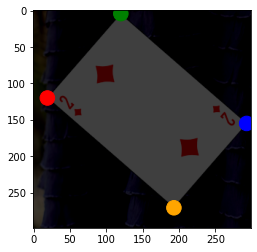

In [7]:
imageId = 7

images, labels, concepts, card_points, card_classes = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True image concepts:", concepts[imageId])
print("True card points:", card_points[imageId])
print("True card classes:", card_classes[imageId])

fig, ax = plt.subplots(1)
ax.imshow(np.asarray(images[imageId].squeeze().permute(1, 2, 0)))
for card in card_points[imageId]:
    for point_no in range(len(card)):
        if point_no == 0:
            ax.add_patch(Circle((card[point_no][0], card[point_no][1]), 10, color='red'))  # top left
        elif point_no == 1: # top right
            ax.add_patch(Circle((card[point_no][0], card[point_no][1]), 10, color='green'))  # top left
        elif point_no == 2: # bottom left
            ax.add_patch(Circle((card[point_no][0], card[point_no][1]), 10, color='orange'))  # top left
        else:
            ax.add_patch(Circle((card[point_no][0], card[point_no][1]), 10, color='blue'))  # bottom right
plt.show()

In [8]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 15:
        XtoC_model_1.append(m)
    elif idx < 29:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device)
XtoC_model_2.to(device)
XtoC_model_3.to(device)

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(256, 5

Predicted concepts: tensor([[-29.6085,  33.0329, -28.5991, -32.9980, -35.2696, -32.2875, -27.9086,
         -23.0144, -36.0987, -31.5004, -40.7288, -36.1370, -29.3984, -14.0790,
          14.3678, -20.0016, -12.0027]], device='cuda:0',
       grad_fn=<AddmmBackward0>)
id: 1, concept name: 2, sig value: 1.0
id: 14, concept name: D, sig value: 0.9999994039535522


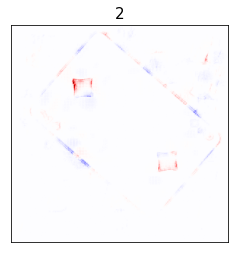

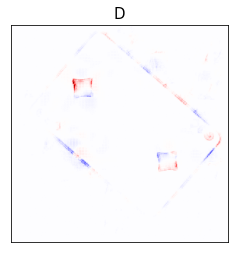

In [21]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")


pred_concepts_readable = torch.nn.Sigmoid()(pred_concepts)
print("Predicted concepts:", pred_concepts)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")
    
# get saliecy maps for top concepts
pred_precent_concepts = []
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        pred_precent_concepts.append((idx, i.item()))

pred_precent_concepts = sorted(pred_precent_concepts, key=lambda x: -x[1])

for i in pred_precent_concepts:
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i[0]] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    

    plt.xticks([])
    plt.yticks([])
    plt.title(label=concept_index_to_string(i[0]), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close()